In [1]:
import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sb
from sklearn.neighbors import KernelDensity
from scipy.spatial.distance import cdist
import scanpy.external as sce
import os
import datetime
import matplotlib.pyplot as pl
from matplotlib import rcParams
from matplotlib import colors
from fcsparser import parse
import pytometry as pm

sc.settings.verbosity = 3

In [129]:
data_path = "/public/users/xueyupeng/VZV/lvzhu/"

In [3]:
fcs_files = []

for root, dirs, files in os.walk(data_path):
    # 只在路径中包含 separate 的目录中找 fcs
    if os.path.basename(root) == "separate":
        for file in files:
            if file.endswith(".fcs"):
                fcs_files.append(os.path.join(root, file))

print(len(fcs_files))
fcs_files[:5]

156


['/public/users/xueyupeng/VZV/lvzhu/20260129/separate/A004-V1_20260129-1_2-3.fcs',
 '/public/users/xueyupeng/VZV/lvzhu/20260129/separate/A007-V0_20260129-2_5-3.fcs',
 '/public/users/xueyupeng/VZV/lvzhu/20260129/separate/A016-V1_20260129-4_6-3.fcs',
 '/public/users/xueyupeng/VZV/lvzhu/20260129/separate/A007-V3_20260129-2_7-3.fcs',
 '/public/users/xueyupeng/VZV/lvzhu/20260129/separate/A005-V4_20260129-1_8-3.fcs']

In [4]:
records = []
for f in fcs_files:
    try:
        meta, data = parse(f, reformat_meta=True)
        cell_count = data.shape[0]
        records.append({
            "file": f,
            "cells": cell_count
        })
    except Exception as e:
        print(f"无法读取文件 {f}: {e}")
print("all files read")
# ===== 保存结果 =====
record_dir = os.path.join(data_path, "record")
os.makedirs(record_dir, exist_ok=True)
out_file = os.path.join(record_dir, "cell_counts.csv")
pd.DataFrame(records).to_csv(out_file, index=False)
print(f"Saved to: {out_file}")

all files read
Saved to: /public/users/xueyupeng/VZV/lvzhu/record/cell_counts.csv


In [5]:
adatas = []

for file_path in fcs_files:
    # ===== 取纯文件名 =====
    file_name = os.path.basename(file_path)
    # A004-V1_20260129-1_2-3.fcs
    prefix = file_name.split("_")[0]        # A004-V1
    ID = prefix.split("-")[0]               # A004
    Visit = prefix.split("-")[1]            # V1
    Sample = f"{ID}_{Visit}"
    # ===== 读取FCS =====
    adata = pm.io.read_fcs(file_path)
    # ===== 写metadata =====
    adata.obs["ID"] = ID
    adata.obs["Visit"] = Visit
    adata.obs["Sample"] = Sample
    # ===== CyTOF signal split =====
    pm.pp.split_signal(
        adata,
        var_key="channel",
        data_type="cytof"
    )
    adatas.append(adata)
print("Total adatas:", len(adatas))

'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is not in adata.var['signal_type']. Return all.
'area' is 

In [6]:
adatas[0].var_names

Index(['CD45-1_106Cd', 'CD45-2_110Cd', 'CD45-3_111Cd', 'CD8_112Cd',
       'CD3_113In', 'CD45-4_114Cd', 'CD4_115In', 'CD45-5_116Cd', 'CD57_139La',
       'CD56_141Pr', 'IgD_142Nd', 'IFN-a_144Nd', 'CXCL9_146Nd', 'CD86_147Sm',
       'H3K27ac_148Nd', 'IL-1b_149Sm', '4E-BP1_150Nd', 'pS6_151Eu',
       'CCR2_152Sm', 'TNF-a_153Eu', 'IL-4_154Sm', 'CD14_155Gd', 'CASP-8_156Gd',
       'TCR-gd_158Gd', 'CD38_159Tb', 'CD27_160Gd', 'CD123_161Dy',
       'Ki-67_162Dy', 'CXCL10_163Dy', 'Arginase-1_164Dy', 'IL-6_165Ho',
       'MCP-1_166Er', 'CD69_167Er', 'STC1_168Er', 'GZMB_169Tm', 'CD45RA_170Er',
       'HLA-DR_171Yb', 'IFN-g_172Yb', 'CD11c_173Yb', 'CD19_174Yb',
       'pSTAT1_175Lu', 'pSTAT3_176Yb', 'DNA1_191Ir', 'DNA2_193Ir',
       'LIVE_198Pt', 'CD16_209Bi', 'CSR', 'Center', 'Event_Length', 'Offset',
       'Residual', 'Time'],
      dtype='object')

In [7]:
np.random.seed(42)
down_adatas = []
for adata in adatas:
    n_cells = adata.n_obs
    if n_cells > 50000:
        idx = np.random.choice(n_cells, 50000, replace=False)
        adata_sub = adata[idx].copy()
    else:
        adata_sub = adata.copy()
    down_adatas.append(adata_sub)

In [8]:
records = []
for adata in down_adatas:
    sample_name = adata.obs["Sample"].iloc[0]
    n_cells = adata.n_obs
    records.append({
        "Sample": sample_name,
        "Cells": n_cells
    })
df_cells = pd.DataFrame(records)
print(df_cells)

      Sample  Cells
0    A004_V1  50000
1    A007_V0  50000
2    A016_V1  50000
3    A007_V3  50000
4    A005_V4  50000
..       ...    ...
151  A025_V4  50000
152  A033_V4  50000
153  A030_V1  50000
154  A023_V3  50000
155  A030_V4  50000

[156 rows x 2 columns]


In [9]:
# 合并所有 sample
adata_all = ad.concat(
    down_adatas,
    join="outer",        # 保留所有marker
    label="batch",       # 自动生成batch列
    keys=[a.obs["Sample"].iloc[0] for a in down_adatas]
)

print(adata_all)

AnnData object with n_obs × n_vars = 7783039 × 52
    obs: 'ID', 'Visit', 'Sample', 'batch'


/public/users/xueyupeng/.conda/envs/cytof/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [10]:
# 保存原始矩阵
adata_all.layers["raw"] = adata_all.X.copy()
# arcsinh 转换
cofactor = 5
adata_all.X = np.arcsinh(adata_all.X / cofactor)

print("arcsinh finished")

arcsinh finished


In [15]:
adata_all.shape

(7783039, 52)

In [11]:
print("RAW range:",
      adata_all.layers["raw"].min(),
      adata_all.layers["raw"].max())

print("Arcsinh range:",
      adata_all.X.min(),
      adata_all.X.max())

RAW range: -22355.26 349952770.0
Arcsinh range: -9.098526 18.757019


In [172]:
markers = ['CD8_112Cd','CD3_113In',  'CD4_115In', 'CD57_139La', 'CD56_141Pr', 
           'IgD_142Nd', 'IFN-a_144Nd', 'CXCL9_146Nd', 'CD86_147Sm','H3K27ac_148Nd', 
           'IL-1b_149Sm', '4E-BP1_150Nd', 'pS6_151Eu','CCR2_152Sm', 'TNF-a_153Eu', 
           'IL-4_154Sm', 'CD14_155Gd', 'CASP-8_156Gd','TCR-gd_158Gd', 'CD38_159Tb', 
           'CD27_160Gd', 'CD123_161Dy','Ki-67_162Dy', 'CXCL10_163Dy', 'Arginase-1_164Dy', 
           'IL-6_165Ho','MCP-1_166Er', 'CD69_167Er', 'STC1_168Er', 'GZMB_169Tm', 
           'CD45RA_170Er','HLA-DR_171Yb', 'IFN-g_172Yb', 'CD11c_173Yb', 'CD19_174Yb',
       'pSTAT1_175Lu', 'pSTAT3_176Yb',  'CD16_209Bi']

In [13]:
adata_all.write("/public/users/xueyupeng/VZV/lvzhu/record/adata_all_down_50k.h5ad")

In [14]:
mask = adata_all.var_names.isin(markers)

sc.tl.pca(
    adata_all,
    n_comps=30,
    mask_var=mask
)
print(sum(mask))
print(adata_all.var_names[mask])

computing PCA
    with n_comps=30
    finished (0:00:07)
38
Index(['CD8_112Cd', 'CD3_113In', 'CD4_115In', 'CD57_139La', 'CD56_141Pr',
       'IgD_142Nd', 'IFN-a_144Nd', 'CXCL9_146Nd', 'CD86_147Sm',
       'H3K27ac_148Nd', 'IL-1b_149Sm', '4E-BP1_150Nd', 'pS6_151Eu',
       'CCR2_152Sm', 'TNF-a_153Eu', 'IL-4_154Sm', 'CD14_155Gd', 'CASP-8_156Gd',
       'TCR-gd_158Gd', 'CD38_159Tb', 'CD27_160Gd', 'CD123_161Dy',
       'Ki-67_162Dy', 'CXCL10_163Dy', 'Arginase-1_164Dy', 'IL-6_165Ho',
       'MCP-1_166Er', 'CD69_167Er', 'STC1_168Er', 'GZMB_169Tm', 'CD45RA_170Er',
       'HLA-DR_171Yb', 'IFN-g_172Yb', 'CD11c_173Yb', 'CD19_174Yb',
       'pSTAT1_175Lu', 'pSTAT3_176Yb', 'CD16_209Bi'],
      dtype='object')


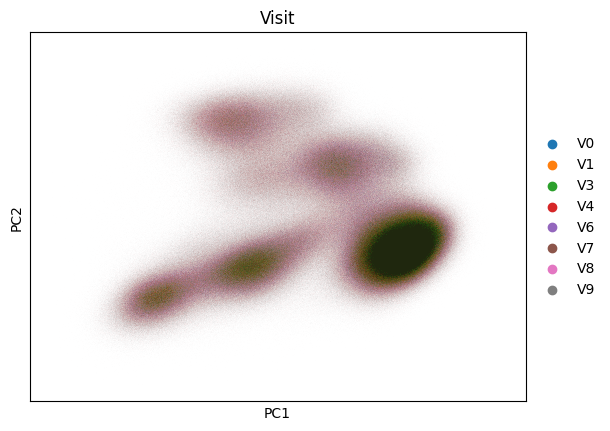

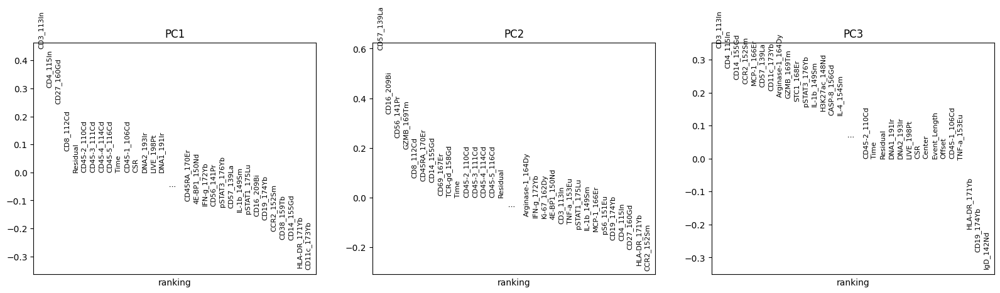

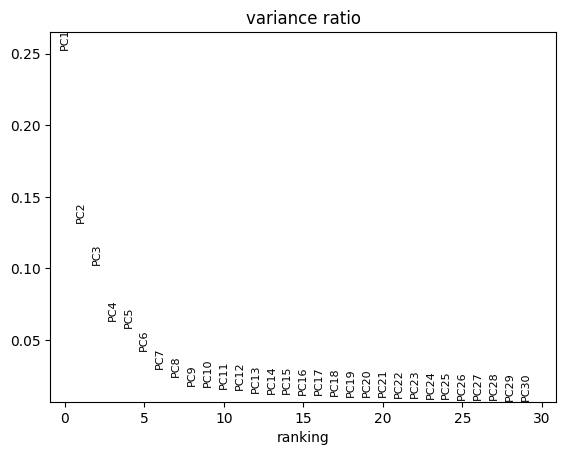

In [16]:
sc.pl.pca_overview(adata_all, color = "Visit")

In [17]:
sc.pp.neighbors(adata_all, n_neighbors=15, n_pcs=10)
print("Neighbors finished")

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:18:43)
Neighbors finished


In [18]:
sc.tl.umap(adata_all)
print("UMAP finished")

computing UMAP


IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (1:51:26)
UMAP finished


In [19]:
sc.tl.leiden(
    adata_all,
    resolution=0.5,
    flavor="igraph",
    n_iterations=2,
    directed=False
)
print("Leiden finished")

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:08:26)
Leiden finished


In [20]:
adata_all.write("/public/users/xueyupeng/VZV/lvzhu/record/adata_all_umap_50k.h5ad")

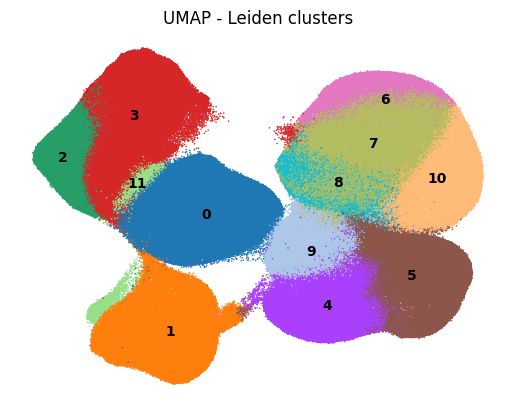

In [21]:
sc.pl.umap(
    adata_all,
    color="leiden",
    legend_loc="on data",
    frameon=False,
    size=5,
    title="UMAP - Leiden clusters"
)

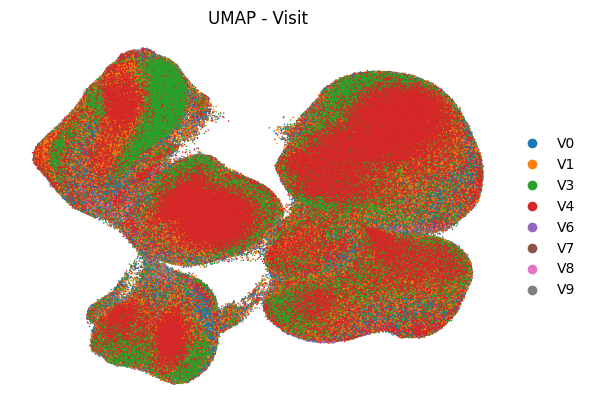

In [22]:
sc.pl.umap(
    adata_all,
    color="Visit",
    frameon=False,
    size=5,
    title="UMAP - Visit"
)

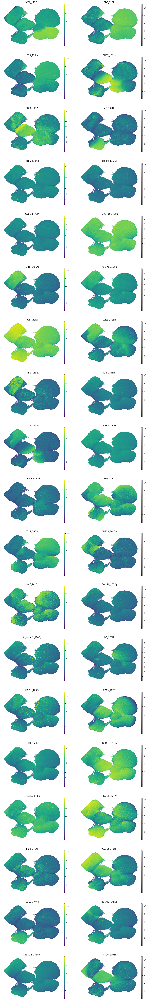

In [23]:
sc.pl.umap(
    adata_all,
    color=markers,
    ncols=2,
    cmap="viridis",
    frameon=False,
    size=5
)

In [24]:
sc.settings.figdir = "/public/users/xueyupeng/VZV/lvzhu/figures"
os.makedirs("/public/users/xueyupeng/VZV/lvzhu/figures", exist_ok=True)

In [88]:
sc.pl.umap(
    adata_all,
    color="leiden",
    legend_loc="on data",
    cmap="viridis",
    frameon=False,
    show=False,
    size=0.1,
    save="_leiden.png"
)

<Axes: title={'center': 'leiden'}, xlabel='UMAP1', ylabel='UMAP2'>

In [89]:
for m in markers:
    sc.pl.umap(
        adata_all,
        color=m,
        cmap="viridis",
        frameon=False,
        show=False,
        size = 0.1,
        save=f"_{m}.png"
    )

In [90]:
for m in markers:
    sc.pl.violin(
        adata_all,
        keys=m,
        groupby="leiden",
        rotation=90,
        stripplot=False,
        show=False,
        save=f"_{m}.png"
    )

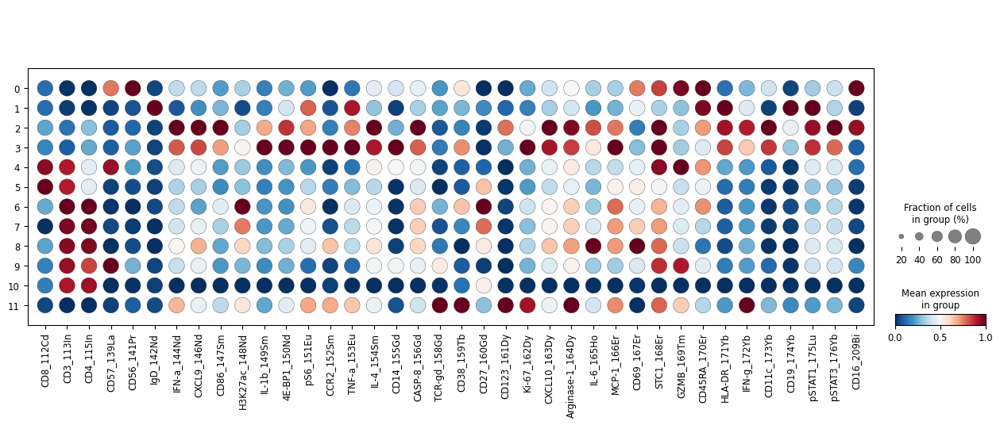

In [158]:
import matplotlib.pyplot as pl

dp = sc.pl.dotplot(
    adata_all,
    var_names=markers,
    groupby="leiden",
    standard_scale="var",
    cmap="RdBu_r",
    return_fig=True
)

dp.savefig("/public/users/xueyupeng/VZV/lvzhu/figures/dotplot_markers.png", dpi=300)

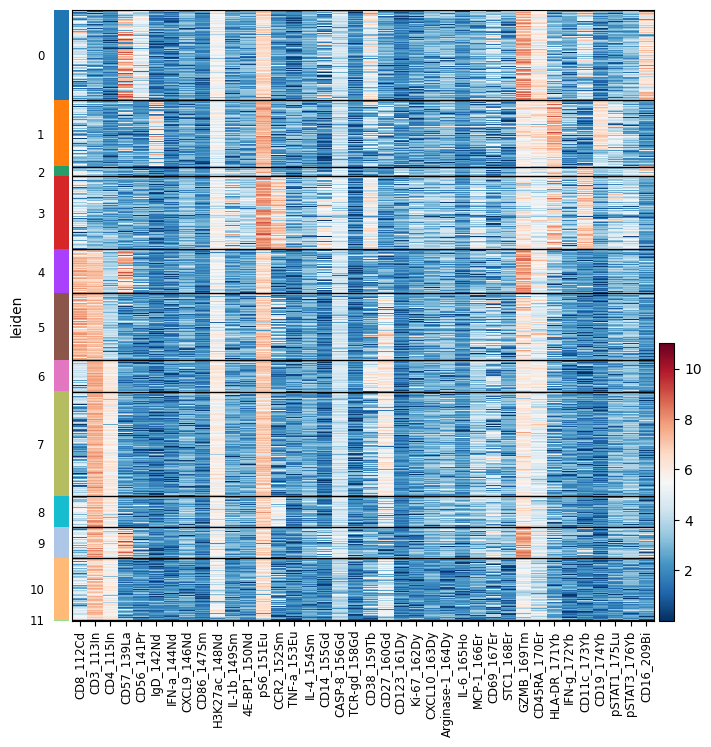

In [166]:
import matplotlib.pyplot as plt

# Plot heatmap without displaying it immediately
dp = sc.pl.heatmap(
    adata_all,                # AnnData object
    var_names=markers,        # Genes or markers to plot
    groupby="leiden",         # The grouping factor (clusters or categories)
    cmap="RdBu_r",            # Colormap for the expression values
    figsize=(8, 8),           # Figure size
    show=False                # Set to False to not display immediately
)

# Access the current axis of the heatmap plot (the actual Axes object)
ax = plt.gca()  # Get the current axis from the plot

# Rotate the x-axis labels
for tick in ax.get_xticklabels():
    tick.set_rotation(45)  # Rotate by 45 degrees

# Save the figure using plt.gcf()
plt.gcf().savefig("/public/users/xueyupeng/VZV/lvzhu/figures/heatmap_markers.png", dpi=300)

In [62]:
adata_all = sc.read_h5ad(
    "/public/users/xueyupeng/VZV/lvzhu/record/adata_all_umap_50k.h5ad"
)
print(adata_all)

AnnData object with n_obs × n_vars = 7783039 × 52
    obs: 'ID', 'Visit', 'Sample', 'batch', 'leiden'
    uns: 'Visit_colors', 'leiden', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'connectivities', 'distances'


/public/users/xueyupeng/.conda/envs/cytof/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [63]:
adata_all.obs_names_make_unique()

In [64]:
# 提取 cluster 11
adata_cl11 = adata_all[adata_all.obs['leiden'] == '11'].copy()

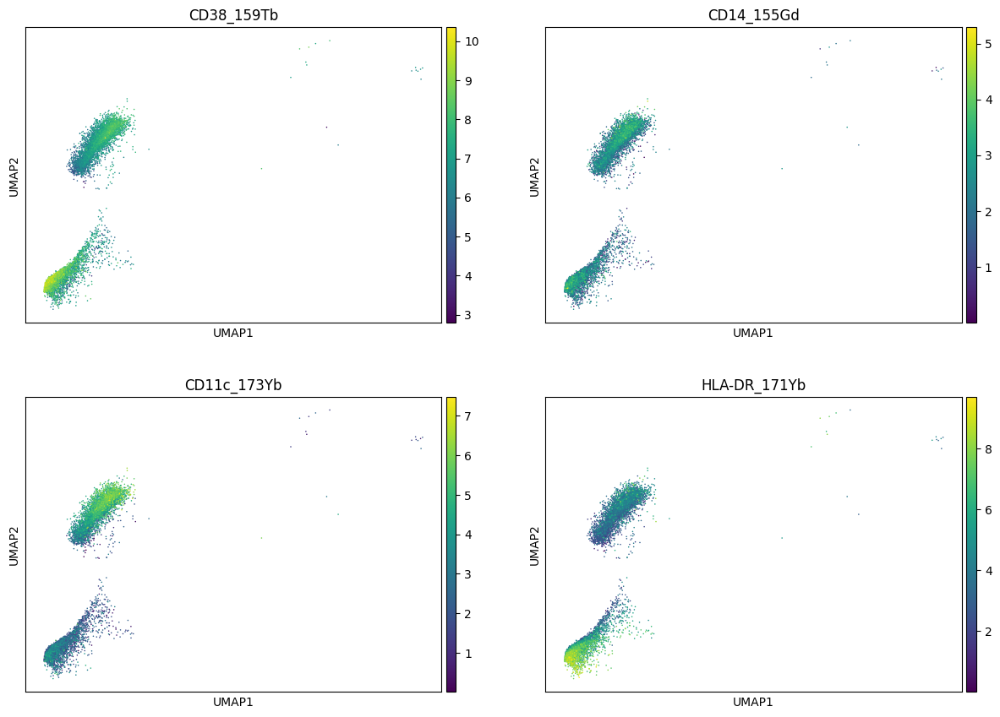

In [65]:
markers_sub = ['CD38_159Tb', 'CD14_155Gd', 'CD11c_173Yb', 'HLA-DR_171Yb']

sc.pl.umap(adata_cl11, color=markers_sub, cmap='viridis', ncols=2, size=5)

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:05)
running Leiden clustering
    finished: found 5 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


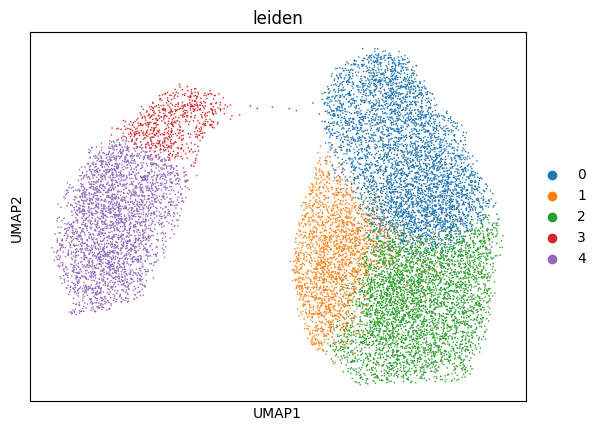

In [66]:
# 先做 neighbors
sc.pp.neighbors(adata_cl11, n_neighbors=15, n_pcs=10)
# 重新 UMAP
sc.tl.umap(adata_cl11)
# 重新聚类
sc.tl.leiden(adata_cl11, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)

sc.pl.umap(adata_cl11, color='leiden', size=5)

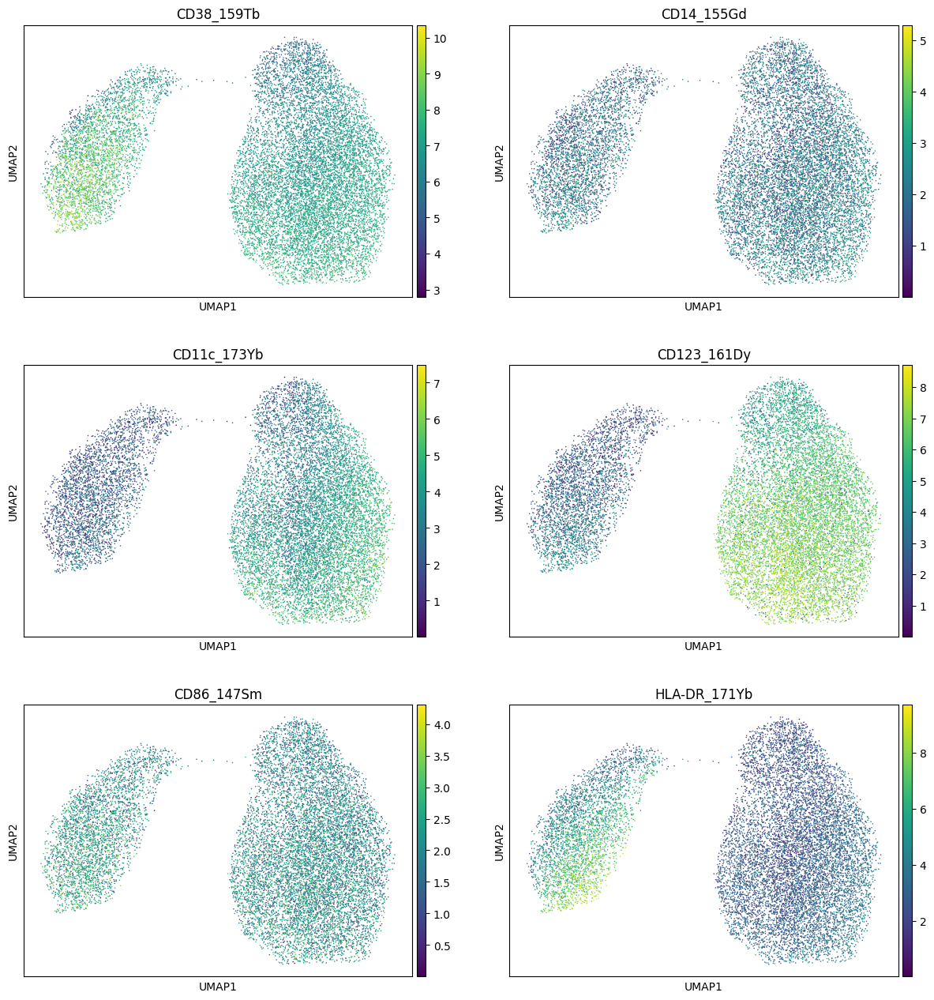

In [67]:
markers_sub = ['CD38_159Tb', 'CD14_155Gd', 'CD11c_173Yb', 'CD123_161Dy', 'CD86_147Sm', 'HLA-DR_171Yb']

sc.pl.umap(adata_cl11, color=markers_sub, cmap='viridis', ncols=2, size=5)

In [68]:
# 假设重新聚类后生成 2 个子群 0 和 1
adata_cl11.obs['celltype'] = adata_cl11.obs['leiden'].map({
    '0': 'DC',
    '1': 'DC',
    '2': 'DC',
    '3': 'Plasma',
    '4': 'Plasma'
})

In [69]:
cluster_anno = {
    "0": "NK",
    "1": "B",
    "2": "DC",
    "3": "Monocyte",
    "4": "CD8T",
    "5": "CD8T",
    "6": "CD4T",
    "7": "CD4T",
    "8": "CD4T",
    "9": "CD4T",
    "10": "CD4T"
}

In [70]:
# 先用原来的 cluster 注释填充
adata_all.obs["celltype"] = adata_all.obs["leiden"].map(cluster_anno)

# 然后用 cluster11 的子注释覆盖对应的细胞
adata_all.obs.loc[adata_cl11.obs_names, 'celltype'] = adata_cl11.obs['celltype']

# 查看结果
adata_all.obs['celltype'].value_counts()

celltype
CD4T        3311530
CD8T        1404275
NK          1152565
Monocyte     932960
B            849851
DC           128381
Plasma         3477
Name: count, dtype: int64

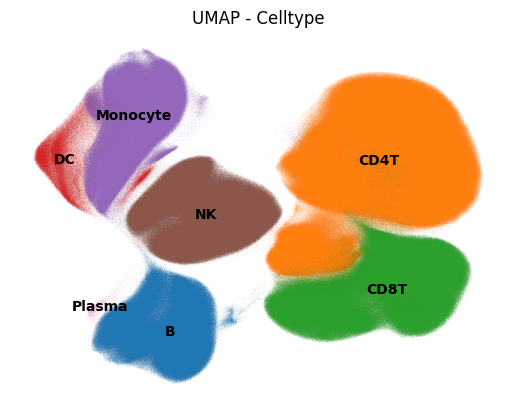

In [93]:
sc.pl.umap(
    adata_all,
    color="celltype",
    legend_loc="on data",
    frameon=False,
    size=0.1,
    title="UMAP - Celltype",
    save=f"_celltype.png"
)

In [72]:
adata_all.obs['Visit'].value_counts()

Visit
V1    1800000
V3    1800000
V4    1800000
V0    1794383
V6     150000
V7     150000
V8     150000
V9     138656
Name: count, dtype: int64

In [73]:
visit_map = {
    'V0': 'V1Day0',
    'V6': 'V1Day0',
    'V1': 'V1Day1',
    'V7': 'V1Day1',
    'V3': 'V2Day0',
    'V8': 'V2Day0',
    'V4': 'V2Day1',
    'V9': 'V2Day1'
}

adata_all.obs['Timepoint'] = adata_all.obs['Visit'].map(visit_map)

In [74]:
adata_all.obs['Timepoint'].value_counts()

Timepoint
V1Day1    1950000
V2Day0    1950000
V1Day0    1944383
V2Day1    1938656
Name: count, dtype: int64

<Axes: title={'center': 'UMAP by Timepoint'}, xlabel='UMAP1', ylabel='UMAP2'>

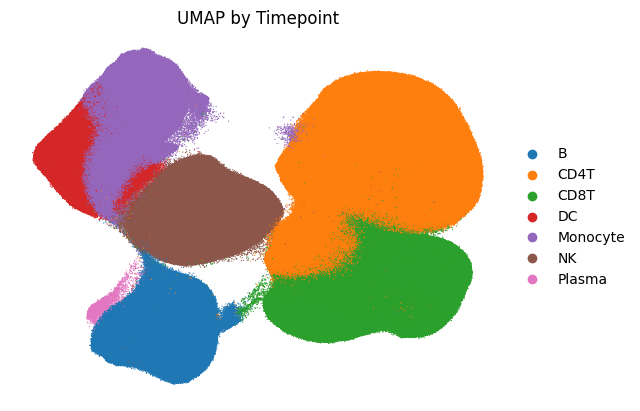

In [76]:
sc.pl.umap(
    adata_all,
    color="celltype",
    groups=None,
    size=3,
    frameon=False,
    ncols=2,
    title="UMAP by Timepoint",
    show=False
)

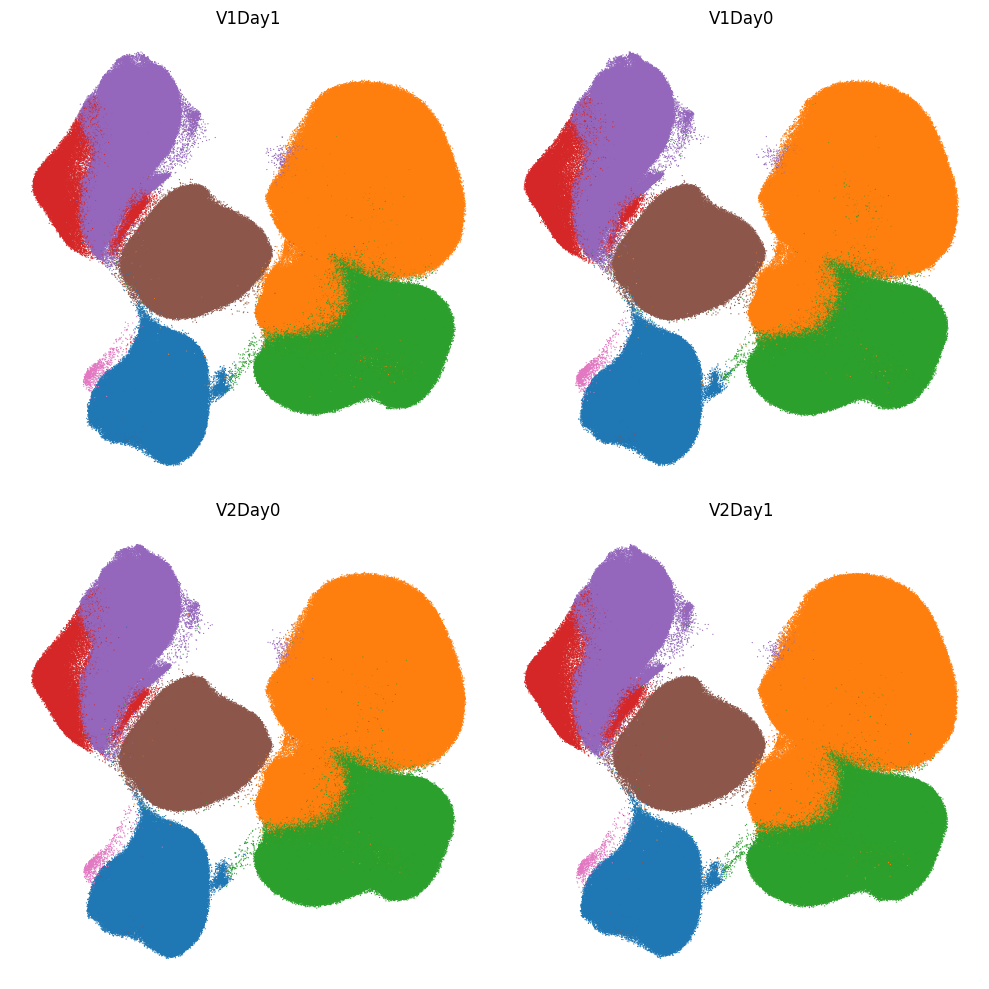

In [79]:
tps = adata_all.obs['Timepoint'].unique()

fig, axes = plt.subplots(
    nrows=int(np.ceil(len(tps)/2)),
    ncols=2,
    figsize=(10, 5*int(np.ceil(len(tps)/2)))
)

axes = axes.flatten()

for i, tp in enumerate(tps):
    
    sc.pl.umap(
        adata_all[adata_all.obs['Timepoint'] == tp],
        color="celltype",
        ax=axes[i],
        show=False,
        frameon=False,
        size=3,
        title=tp,
        legend_loc=None
    )

plt.tight_layout()
plt.savefig("/public/users/xueyupeng/VZV/lvzhu/figures/UMAP_Timepoint_celltype.png", dpi=300)
plt.show()

In [92]:
adata_all.write("/public/users/xueyupeng/VZV/lvzhu/record/adata_all_celltype_50k.h5ad")

In [95]:
df = pd.DataFrame(
    adata_all[:, markers].X,
    columns=markers,
    index=adata_all.obs_names
)

meta = adata_all.obs[['ID','Timepoint','celltype']]

df_all = pd.concat([meta, df], axis=1)

pseudo = (
    df_all
    .groupby(['ID','Timepoint','celltype'])
    .median()
    .reset_index()
)

/tmp/ipykernel_377158/3843851272.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['ID','Timepoint','celltype'])


ValueError: List of boxplot statistics and `positions` values must have same the length

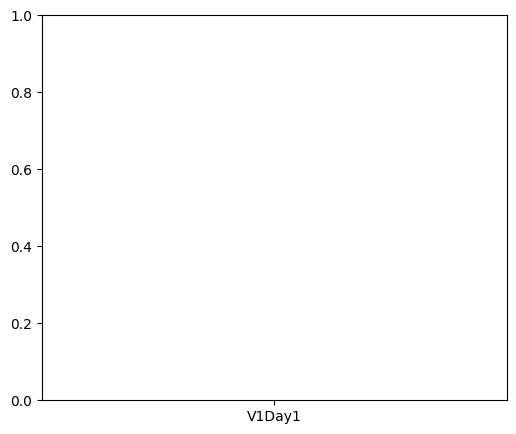

In [112]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ========= 输出目录 =========
base_dir = "/public/users/xueyupeng/VZV/lvzhu/figures_marker_analysis/"
dir1 = os.path.join(base_dir, "1_threshold_distribution")
dir2 = os.path.join(base_dir, "2_positive_ratio")
dir3 = os.path.join(base_dir, "3_positive_median")
dir4 = os.path.join(base_dir, "4_positive_geomean")

for d in [dir1, dir2, dir3, dir4]:
    os.makedirs(d, exist_ok=True)

# ========= 参数 =========
sub_markers = ['IgD_142Nd', 'IFN-a_144Nd', 'CXCL9_146Nd', 'CD86_147Sm','H3K27ac_148Nd', 
               'IL-1b_149Sm', '4E-BP1_150Nd', 'pS6_151Eu','CCR2_152Sm', 'TNF-a_153Eu', 
               'IL-4_154Sm', 'CASP-8_156Gd','CD38_159Tb', 'CD123_161Dy','Ki-67_162Dy', 
               'CXCL10_163Dy', 'Arginase-1_164Dy', 'IL-6_165Ho','MCP-1_166Er', 
               'CD69_167Er', 'STC1_168Er', 'IFN-g_172Yb','pSTAT1_175Lu', 'pSTAT3_176Yb']


timepoints = sorted(adata_all.obs['Timepoint'].unique())
celltypes = sorted(adata_all.obs['celltype'].unique())

# ========= 1️⃣ 计算阈值 =========
v1day0_idx = (adata_all.obs['Timepoint'] == 'V1Day0')
marker_stats = {}

for ct in celltypes:
    ct_idx = v1day0_idx & (adata_all.obs['celltype'] == ct)
    for marker in sub_markers:
        if marker not in adata_all.var_names:
            continue
        idx_marker = adata_all.var_names.get_loc(marker)
        data_vec = adata_all[ct_idx, idx_marker].X
        data_vec = data_vec.toarray().flatten() if hasattr(data_vec, "toarray") else np.ravel(data_vec)

        median = np.median(data_vec)
        sd = np.std(data_vec)
        marker_stats[(ct, marker)] = median + 2*sd

# ========= 2️⃣ 统计 =========
records = []

for ct in celltypes:
    for marker in sub_markers:
        if (ct, marker) not in marker_stats:
            continue

        idx_marker = adata_all.var_names.get_loc(marker)
        threshold = marker_stats[(ct, marker)]

        for sample in adata_all.obs['Sample'].unique():
            for tp in timepoints:

                mask = (
                    (adata_all.obs['Sample'] == sample) &
                    (adata_all.obs['Timepoint'] == tp) &
                    (adata_all.obs['celltype'] == ct)
                )

                if mask.sum() == 0:
                    continue

                data_vec = adata_all[mask, idx_marker].X
                data_vec = data_vec.toarray().flatten() if hasattr(data_vec, "toarray") else np.ravel(data_vec)

                pos = data_vec[data_vec > threshold]

                pos_ratio = len(pos) / len(data_vec) * 100

                pos_median = np.median(pos) if len(pos) > 0 else np.nan

                # 几何平均数（避免0）
                pos_geomean = np.exp(np.mean(np.log(pos + 1e-9))) if len(pos) > 0 else np.nan

                records.append({
                    "Sample": sample,
                    "Timepoint": tp,
                    "Celltype": ct,
                    "Marker": marker,
                    "Positive_Ratio_%": pos_ratio,
                    "Positive_Median": pos_median,
                    "Positive_Geomean": pos_geomean
                })

marker_summary = pd.DataFrame(records)

In [113]:
# ========= 保存路径 =========
save_dir = "/public/users/xueyupeng/VZV/lvzhu/record/"
os.makedirs(save_dir, exist_ok=True)

# ========= 1️⃣ 保存 marker_summary =========
marker_summary_path = os.path.join(save_dir, "marker_summary_celltype.csv")
marker_summary.to_csv(marker_summary_path, index=False)
print(f"✓ marker_summary 已保存: {marker_summary_path}")

# ========= 2️⃣ 保存阈值表 =========
# dict → DataFrame
threshold_df = pd.DataFrame([
    {
        "Celltype": ct,
        "Marker": marker,
        "Threshold": thresh
    }
    for (ct, marker), thresh in marker_stats.items()
])

threshold_path = os.path.join(save_dir, "marker_thresholds_celltype.csv")
threshold_df.to_csv(threshold_path, index=False)
print(f"✓ 阈值表已保存: {threshold_path}")

# ========= 3️⃣ 基本信息检查 =========
print("\n=== 数据概览 ===")
print("marker_summary shape:", marker_summary.shape)
print("threshold_df shape:", threshold_df.shape)

print("\n=== marker_summary 前5行 ===")
print(marker_summary.head())

print("\n=== threshold_df 前5行 ===")
print(threshold_df.head())

✓ marker_summary 已保存: /public/users/xueyupeng/VZV/lvzhu/record/marker_summary_celltype.csv
✓ 阈值表已保存: /public/users/xueyupeng/VZV/lvzhu/record/marker_thresholds_celltype.csv

=== 数据概览 ===
marker_summary shape: (26208, 7)
threshold_df shape: (168, 3)

=== marker_summary 前5行 ===
    Sample Timepoint Celltype     Marker  Positive_Ratio_%  Positive_Median  \
0  A004_V1    V1Day1        B  IgD_142Nd               0.0              NaN   
1  A007_V0    V1Day0        B  IgD_142Nd               0.0              NaN   
2  A016_V1    V1Day1        B  IgD_142Nd               0.0              NaN   
3  A007_V3    V2Day0        B  IgD_142Nd               0.0              NaN   
4  A005_V4    V2Day1        B  IgD_142Nd               0.0              NaN   

   Positive_Geomean  
0               NaN  
1               NaN  
2               NaN  
3               NaN  
4               NaN  

=== threshold_df 前5行 ===
  Celltype         Marker  Threshold
0        B      IgD_142Nd   9.951273
1        B    IF

In [ ]:
# ========= 图1：阈值分布（按 celltype） =========
for ct in celltypes:
    for marker in sub_markers:

        if marker not in adata_all.var_names:
            continue
        if (ct, marker) not in marker_stats:
            continue

        idx_marker = adata_all.var_names.get_loc(marker)
        threshold = marker_stats[(ct, marker)]

        plt.figure(figsize=(6,5))

        # 每个 sample 一条曲线
        for sample in adata_all.obs['Sample'].unique():
            mask = (
                (adata_all.obs['Sample'] == sample) &
                (adata_all.obs['celltype'] == ct)
            )

            if mask.sum() == 0:
                continue

            data_vec = adata_all[mask, idx_marker].X
            data_vec = data_vec.toarray().flatten() if hasattr(data_vec, "toarray") else np.ravel(data_vec)

            # 防止全0或常数导致kde报错
            if np.std(data_vec) == 0:
                continue

            sns.kdeplot(data_vec, alpha=0.3)

        # 🔴 阈值线
        plt.axvline(threshold, color='red', linestyle='--', linewidth=2)

        plt.title(f"{marker} ({ct})")
        plt.xlabel("Expression")
        plt.ylabel("Density")

        plt.legend([],[],frameon=False)
        plt.tight_layout()

        plt.savefig(f"{dir1}/{marker}_{ct}_distribution.png", dpi=300)
        plt.close()

In [116]:
def plot_box_scatter(df, y, ylabel, save_dir, marker, ct):

    # ❗ 固定时间顺序
    timepoint_order = ["V1Day0", "V1Day1", "V2Day0", "V2Day1"]

    # ❗ 去掉 NaN
    df = df.dropna(subset=[y])

    # ❗ 只保留定义顺序中的时间点
    df = df[df["Timepoint"].isin(timepoint_order)]

    # ❗ 每个 timepoint 至少2个点
    valid_counts = df.groupby("Timepoint")[y].count()
    if (valid_counts < 2).any():
        return

    # ❗ log轴不能有0或负值
    df = df[df[y] > 0]
    if df.shape[0] < 3:
        return

    plt.figure(figsize=(6,5))

    # ✅ 箱线图
    sns.boxplot(
        data=df,
        x="Timepoint",
        y=y,
        order=timepoint_order,   # ⭐ 固定顺序
        color="lightgray",
        showfliers=False
    )

    # ✅ 散点
    sns.stripplot(
        data=df,
        x="Timepoint",
        y=y,
        order=timepoint_order,
        hue="Sample",
        dodge=False,
        size=5,
        alpha=0.8,
        jitter=True
    )

    # ✅ log 轴
    plt.yscale("log")

    plt.ylabel(ylabel + " (log scale)")
    plt.xlabel("Timepoint")
    plt.title(f"{marker} ({ct})")

    # 去掉图例
    plt.legend([], [], frameon=False)

    plt.tight_layout()
    plt.savefig(f"{save_dir}/{marker}_{ct}.png", dpi=300)
    plt.close()

In [117]:
for ct in celltypes:
    for marker in sub_markers:

        df = marker_summary[
            (marker_summary["Marker"] == marker) &
            (marker_summary["Celltype"] == ct)
        ]

        if df.empty:
            continue

        # 图2：阳性比例
        plot_box_scatter(df, "Positive_Ratio_%", "Positive Ratio (%)", dir2, marker, ct)

        # 图3：阳性中位数
        plot_box_scatter(df, "Positive_Median", "Median Expression", dir3, marker, ct)

        # 图4：几何平均数
        plot_box_scatter(df, "Positive_Geomean", "Geometric Mean", dir4, marker, ct)

print("✅ 全部图片已保存")

✅ 全部图片已保存


In [213]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import os
import re

# ========= 从 Sample 提取 ID =========
def extract_id(sample):
    # A004_V3 -> A004
    return re.sub(r"_V\d+$", "", sample)

# 添加 ID 列
marker_summary["ID"] = marker_summary["Sample"].apply(extract_id)

# ========= 参数 =========
timepoint_pairs = [
    ("V1Day0", "V1Day1"),
    ("V2Day0", "V2Day1")
]

alpha = 0.05
results = []

# ========= 主循环 =========
celltypes = marker_summary["Celltype"].dropna().unique()
markers = marker_summary["Marker"].dropna().unique()

for ct in celltypes:
    for marker in markers:

        df = marker_summary[
            (marker_summary["Celltype"] == ct) &
            (marker_summary["Marker"] == marker)
        ]

        if df.empty:
            continue

        for tp1, tp2 in timepoint_pairs:

            df1 = df[df["Timepoint"] == tp1]
            df2 = df[df["Timepoint"] == tp2]

            if df1.empty or df2.empty:
                continue

            # ========= 用 ID 配对 =========
            common_IDs = set(df1["ID"]).intersection(set(df2["ID"]))

            if len(common_IDs) < 3:
                continue

            df1_id = df1[df1["ID"].isin(common_IDs)].set_index("ID")
            df2_id = df2[df2["ID"].isin(common_IDs)].set_index("ID")

            df1_id = df1_id.sort_index()
            df2_id = df2_id.sort_index()

            for metric in ["Positive_Ratio_%", "Positive_Median", "Positive_Geomean"]:

                if metric not in df.columns:
                    continue

                x = df1_id[metric]
                y = df2_id[metric]

                common = x.index.intersection(y.index)

                if len(common) < 3:
                    continue

                x = x.loc[common].dropna()
                y = y.loc[common].dropna()

                # 再次对齐
                common = x.index.intersection(y.index)
                x = x.loc[common]
                y = y.loc[common]

                if len(x) < 3:
                    continue

                # 跳过无变化
                if np.all(x == y):
                    continue

                # 跳过常数
                if x.nunique() < 2 or y.nunique() < 2:
                    continue

                try:
                    stat, p = wilcoxon(x, y)
                except Exception:
                    continue

                results.append({
                    "Celltype": ct,
                    "Marker": marker,
                    "Comparison": f"{tp1} vs {tp2}",
                    "Metric": metric,
                    "N": len(common),
                    "Mean_1": x.mean(),
                    "Mean_2": y.mean(),
                    "Median_1": x.median(),
                    "Median_2": y.median(),
                    "p_value": p
                })

# ========= 转 DataFrame =========
results_df = pd.DataFrame(results)

print(f"Total valid tests: {len(results_df)}")

# ========= FDR 校正 =========
if not results_df.empty and "p_value" in results_df.columns:
    results_df["p_adj"] = multipletests(results_df["p_value"], method="fdr_bh")[1]
    results_df = results_df.sort_values("p_adj")
    results_sig = results_df[results_df["p_adj"] < alpha]
else:
    print("⚠️ 没有任何统计结果（请检查数据）")
    results_df["p_adj"] = []
    results_sig = results_df.copy()

# ========= 保存 =========
save_path = "/public/users/xueyupeng/VZV/lvzhu/record/significant_markers_with_FDR.xlsx"
os.makedirs(os.path.dirname(save_path), exist_ok=True)

with pd.ExcelWriter(save_path) as writer:
    results_df.to_excel(writer, sheet_name="all_results", index=False)
    results_sig.to_excel(writer, sheet_name="significant_only", index=False)

print(f"✓ 保存完成: {save_path}")
print(f"✓ 总结果数: {len(results_df)}")
print(f"✓ 显著结果数 (FDR < {alpha}): {len(results_sig)}")

Total valid tests: 903
✓ 保存完成: /public/users/xueyupeng/VZV/lvzhu/record/significant_markers_with_FDR.xlsx
✓ 总结果数: 903
✓ 显著结果数 (FDR < 0.05): 31


In [128]:
print(results_df)

    Celltype         Marker        Comparison            Metric   N    Mean_1  \
255     CD4T     CD69_167Er  V2Day0 vs V2Day1  Positive_Ratio_%  39  1.694270   
399     CD8T     CD69_167Er  V2Day0 vs V2Day1  Positive_Ratio_%  39  2.367151   
820       NK    IFN-g_172Yb  V2Day0 vs V2Day1  Positive_Ratio_%  39  1.998717   
808       NK     CD69_167Er  V2Day0 vs V2Day1  Positive_Ratio_%  39  1.012551   
333     CD8T     CCR2_152Sm  V2Day0 vs V2Day1  Positive_Ratio_%  39  6.974940   
..       ...            ...               ...               ...  ..       ...   
501       DC    Ki-67_162Dy  V2Day0 vs V2Day1  Positive_Geomean  29  5.484765   
837   Plasma      IgD_142Nd  V1Day0 vs V1Day1  Positive_Geomean   6  6.314094   
483       DC   CASP-8_156Gd  V2Day0 vs V2Day1  Positive_Ratio_%  39  0.004904   
130        B   pSTAT1_175Lu  V2Day0 vs V2Day1   Positive_Median  35  6.791518   
451       DC  H3K27ac_148Nd  V2Day0 vs V2Day1  Positive_Ratio_%  39  0.009522   

       Mean_2  Median_1  Me

In [135]:
import pandas as pd
import os

# ========= 输入数据 =========
df = adata_all.obs.copy()

# ========= 基础清洗 =========
df = df.dropna(subset=["Sample", "celltype"])

# ========= 1️⃣ 计算每个 Sample × Celltype 的计数 =========
cell_counts = (
    df.groupby(["Sample", "celltype"])
    .size()
    .reset_index(name="Count")
)

# ========= 2️⃣ 计算每个 Sample 的总细胞数 =========
total_counts = (
    df.groupby("Sample")
    .size()
    .reset_index(name="Total")
)

# ========= 3️⃣ 提取 Sample 级别的元信息 =========
meta = (
    df[["Sample", "ID", "Visit", "Timepoint"]]
    .drop_duplicates()
)

# ========= 4️⃣ 合并 =========
merged = pd.merge(cell_counts, total_counts, on="Sample")
merged = pd.merge(merged, meta, on="Sample", how="left")

# ========= 5️⃣ 计算比例 =========
merged["Proportion"] = merged["Count"] / merged["Total"]
merged["Proportion_%"] = merged["Proportion"] * 100

# ========= 6️⃣ 透视表 =========
pivot_prop = merged.pivot_table(
    index="Sample",
    columns="celltype",
    values="Proportion",
    fill_value=0
)

pivot_count = merged.pivot_table(
    index="Sample",
    columns="celltype",
    values="Count",
    fill_value=0
)

# ========= 7️⃣ 保存 =========
save_path = "/public/users/xueyupeng/VZV/lvzhu/record/celltype_proportion.xlsx"
os.makedirs(os.path.dirname(save_path), exist_ok=True)

with pd.ExcelWriter(save_path) as writer:
    merged.to_excel(writer, sheet_name="long_format", index=False)
    pivot_prop.to_excel(writer, sheet_name="proportion_pivot")
    pivot_count.to_excel(writer, sheet_name="count_pivot")

print(f"✓ 保存完成: {save_path}")
print(f"✓ merged shape: {merged.shape}")

/tmp/ipykernel_377158/642286569.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["Sample", "celltype"])
/tmp/ipykernel_377158/642286569.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Sample")
/tmp/ipykernel_377158/642286569.py:39: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_prop = merged.pivot_table(
/tmp/ipykernel_377158/642286569.py:46: FutureWarning: The default value of observed=False is deprecated and 

✓ 保存完成: /public/users/xueyupeng/VZV/lvzhu/record/celltype_proportion.xlsx
✓ merged shape: (1092, 9)


细胞类型比例随时间趋势，配对样本wilcox检验。

In [143]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# ========= 路径 =========
input_path = "/public/users/xueyupeng/VZV/lvzhu/record/celltype_proportion.xlsx"
save_dir = "/public/users/xueyupeng/VZV/lvzhu/celltype_time_boxplot/"
os.makedirs(save_dir, exist_ok=True)

# ========= 读取数据 =========
df = pd.read_excel(input_path, sheet_name="long_format")

df = df[["Sample", "celltype", "Proportion", "ID", "Timepoint"]].dropna()

# ========= Timepoint 顺序 =========
time_order = ["V1Day0", "V1Day1", "V2Day0", "V2Day1"]
df["Timepoint"] = pd.Categorical(df["Timepoint"], categories=time_order, ordered=True)

# ========= 比较组 =========
comparisons = [
    ("V1Day0", "V1Day1"),
    ("V2Day0", "V2Day1"),
    ("V1Day0", "V2Day1")
]

# ========= 显著性标注 =========
def add_sig(ax, x1, x2, y, p):
    if p < 0.001:
        text = "***"
    elif p < 0.01:
        text = "**"
    elif p < 0.05:
        text = "*"
    else:
        text = "ns"

    ax.plot([x1, x1, x2, x2], [y, y*1.01, y*1.01, y], color="black", lw=1.5)
    ax.text((x1+x2)/2, y*1.02, text, ha="center", color="black")

# ========= 主循环 =========
celltypes = df["celltype"].unique()

for ct in celltypes:

    sub = df[df["celltype"] == ct].copy()

    plt.figure(figsize=(8,6))

    # ===== 箱线图（黑色）=====
    ax = sns.boxplot(
        data=sub,
        x="Timepoint",
        y="Proportion",
        order=time_order,
        color="white",              # 填充白色
        boxprops=dict(edgecolor="black"),
        medianprops=dict(color="black"),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        showfliers=False
    )

    # ===== 散点（黑色）=====
    sns.stripplot(
        data=sub,
        x="Timepoint",
        y="Proportion",
        order=time_order,
        color="black",
        size=4,
        alpha=0.8,
        jitter=True
    )

    plt.title(f"{ct} proportion over time")
    plt.ylabel("Proportion", color="black")
    plt.xlabel("Timepoint", color="black")

    # 坐标轴字体黑色
    ax.tick_params(axis='x', colors='black')
    ax.tick_params(axis='y', colors='black')

    # 去掉 legend（或也可设为黑色）
    plt.legend([], [], frameon=False)

    # ========= 统计 =========
    y_max = sub["Proportion"].max()
    y_base = y_max * 1.01
    step = y_max * 0.05

    for i, (tp1, tp2) in enumerate(comparisons):

        df1 = sub[sub["Timepoint"] == tp1]
        df2 = sub[sub["Timepoint"] == tp2]

        if df1.empty or df2.empty:
            continue

        common_ids = set(df1["ID"]).intersection(set(df2["ID"]))

        if len(common_ids) < 3:
            continue

        df1_id = df1[df1["ID"].isin(common_ids)].set_index("ID")
        df2_id = df2[df2["ID"].isin(common_ids)].set_index("ID")

        df1_id = df1_id.sort_index()
        df2_id = df2_id.sort_index()

        x = df1_id["Proportion"]
        y = df2_id["Proportion"]

        common = x.index.intersection(y.index)

        if len(common) < 3:
            continue

        x = x.loc[common]
        y = y.loc[common]

        try:
            stat, p = wilcoxon(x, y)
        except:
            continue

        x1 = time_order.index(tp1)
        x2 = time_order.index(tp2)
        y_pos = y_base + i * step

        add_sig(ax, x1, x2, y_pos, p)

    plt.tight_layout()

    save_path = os.path.join(save_dir, f"{ct}.png")
    plt.savefig(save_path, dpi=300)
    plt.close()

print(f"✓ 所有图已保存到: {save_dir}")

✓ 所有图已保存到: /public/users/xueyupeng/VZV/lvzhu/celltype_time_boxplot/


In [168]:
adata_all

AnnData object with n_obs × n_vars = 7783039 × 52
    obs: 'ID', 'Visit', 'Sample', 'batch', 'leiden', 'celltype', 'Timepoint', 'IgD_142Nd_status', 'IFN-a_144Nd_status', 'CXCL9_146Nd_status', 'CD86_147Sm_status', 'H3K27ac_148Nd_status', 'IL-1b_149Sm_status', '4E-BP1_150Nd_status', 'pS6_151Eu_status', 'CCR2_152Sm_status', 'TNF-a_153Eu_status', 'IL-4_154Sm_status', 'CASP-8_156Gd_status', 'CD38_159Tb_status', 'CD123_161Dy_status', 'Ki-67_162Dy_status', 'CXCL10_163Dy_status', 'Arginase-1_164Dy_status', 'IL-6_165Ho_status', 'MCP-1_166Er_status', 'CD69_167Er_status', 'STC1_168Er_status', 'IFN-g_172Yb_status', 'pSTAT1_175Lu_status', 'pSTAT3_176Yb_status'
    uns: 'Visit_colors', 'leiden', 'neighbors', 'pca', 'umap', 'celltype_colors', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'connectivities', 'distances'

In [217]:
markers = ['CD8_112Cd','CD3_113In',  'CD4_115In', 'CD57_139La', 'CD56_141Pr', 
           'IgD_142Nd', 'IFN-a_144Nd', 'CXCL9_146Nd', 'CD86_147Sm','H3K27ac_148Nd', 
           'IL-1b_149Sm', '4E-BP1_150Nd', 'pS6_151Eu','CCR2_152Sm', 'TNF-a_153Eu', 
           'IL-4_154Sm', 'CD14_155Gd', 'CASP-8_156Gd','TCR-gd_158Gd', 'CD38_159Tb', 
           'CD27_160Gd', 'CD123_161Dy','Ki-67_162Dy', 'CXCL10_163Dy', 'Arginase-1_164Dy', 
           'IL-6_165Ho','MCP-1_166Er', 'CD69_167Er', 'STC1_168Er', 'GZMB_169Tm', 
           'CD45RA_170Er','HLA-DR_171Yb', 'IFN-g_172Yb', 'CD11c_173Yb', 'CD19_174Yb',
       'pSTAT1_175Lu', 'pSTAT3_176Yb',  'CD16_209Bi']

computing PCA
    with n_comps=30
    finished (0:00:01)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:33)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:08:44)
running Leiden clustering
    finished: found 10 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:39)


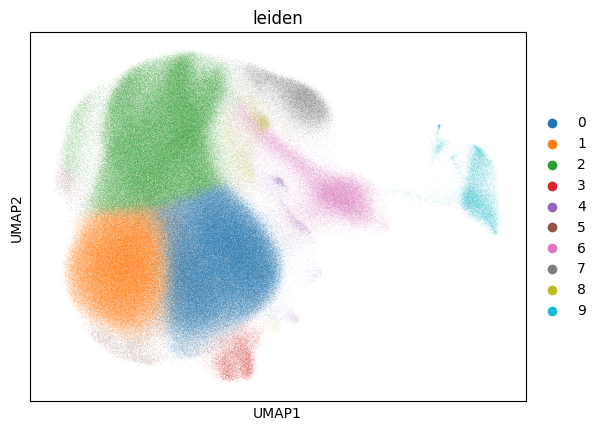

In [218]:
import scanpy as sc

# Filter the AnnData object by specific celltypes
celltypes_of_interest = ['Monocyte']

adata_filtered = adata_all[adata_all.obs['celltype'].isin(celltypes_of_interest)].copy()

mask = adata_filtered.var_names.isin(markers)

# Perform PCA (if not already performed)
sc.tl.pca(adata_filtered, svd_solver='arpack', n_comps=30,mask_var=mask)

# Compute the neighborhood graph
sc.pp.neighbors(adata_filtered, n_neighbors=10, use_rep='X_pca')

# Perform UMAP (if not already performed)
sc.tl.umap(adata_filtered)

# Perform clustering (e.g., Leiden clustering)
sc.tl.leiden(
    adata_filtered,
    resolution=0.5,
    flavor="igraph",
    n_iterations=2,
    directed=False
)

# You can also visualize the UMAP with Leiden clustering results
sc.pl.umap(adata_filtered, color=['leiden'])

In [176]:
# Annotate the clusters (optional step depending on your goal)
# For example, use differential expression to identify marker genes
sc.tl.rank_genes_groups(adata_filtered, 'leiden', method='t-test')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)


In [183]:
markers_mono = ['CD14_155Gd', 'CCR2_152Sm', 'MCP-1_166Er', 'CD16_209Bi']

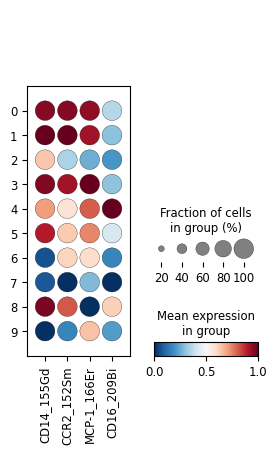

In [188]:
import matplotlib.pyplot as pl

dp = sc.pl.dotplot(
    adata_filtered,
    var_names=markers_mono,
    groupby="leiden",
    standard_scale="var",
    cmap="RdBu_r",
    return_fig=True
)
dp.savefig("/public/users/xueyupeng/VZV/lvzhu/figures/dotplot_markers_Mono.png", dpi=300)

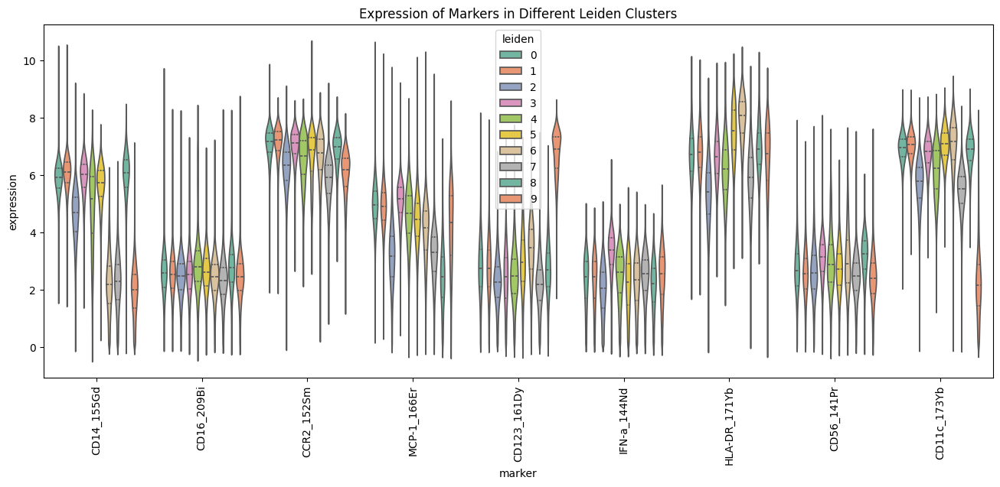

In [246]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 选择需要的小提琴图标记物
markers_mono = ['CD14_155Gd', 'CD16_209Bi', 'CCR2_152Sm', 'MCP-1_166Er','CD123_161Dy','IFN-a_144Nd','HLA-DR_171Yb','CD56_141Pr','CD11c_173Yb']

# 获取标记物的表达数据
data_long = adata_filtered.obs[['leiden']].copy()
for marker in markers_mono:
    data_long[marker] = adata_filtered[:, marker].X.toarray().flatten()  # 获取表达数据并转换为扁平化的数组

# 将数据转换为长格式
data_long = pd.melt(data_long, id_vars=['leiden'], value_vars=markers_mono,
                    var_name='marker', value_name='expression')

# 绘制小提琴图
plt.figure(figsize=(16, 6))
sns.violinplot(x='marker', y='expression', hue='leiden', data=data_long, split=False, inner="quart",
               palette="Set2", dodge=True)
plt.xticks(rotation=90)
plt.title("Expression of Markers in Different Leiden Clusters")
plt.show()

In [225]:
# 统计每个cluster的细胞数
cluster_counts = adata_filtered.obs['leiden'].value_counts()

# 显示结果
print(cluster_counts)

leiden
0    303427
2    279916
1    205045
6     55467
7     30350
9     19549
3     14652
8     10331
5      8029
4      6194
Name: count, dtype: int64


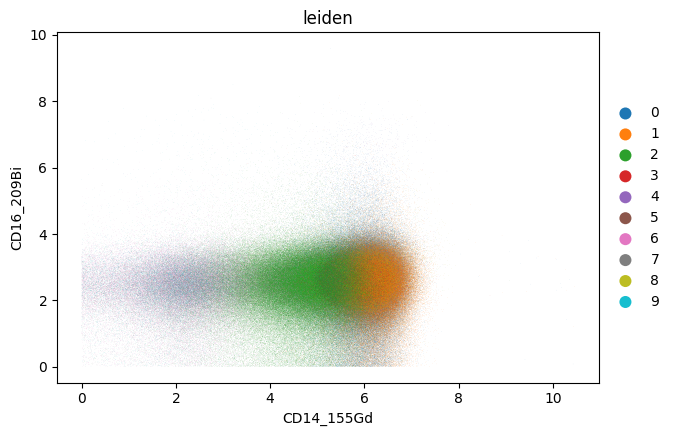

In [220]:
sc.pl.scatter(
    adata_filtered,
    x='CD14_155Gd',
    y='CD16_209Bi',
    color='leiden'
)

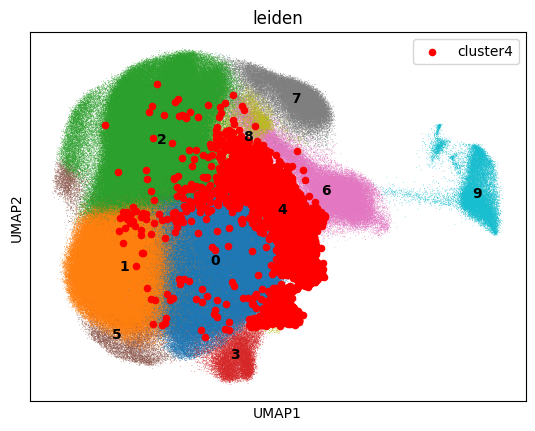

In [224]:
import scanpy as sc
import numpy as np

# 获取 cluster5 的mask
mask = adata_filtered.obs['leiden'] == '4'

# 先画所有点（灰色）
sc.pl.umap(
    adata_filtered,
    color='leiden',
    legend_loc='on data',
    size=1,
    show=False
)

# 在当前图上叠加 cluster5（红色）
import matplotlib.pyplot as plt

umap = adata_filtered.obsm['X_umap']

plt.scatter(
    umap[mask, 0],
    umap[mask, 1],
    c='red',
    s=20,
    label='cluster4'
)

plt.legend()
plt.show()

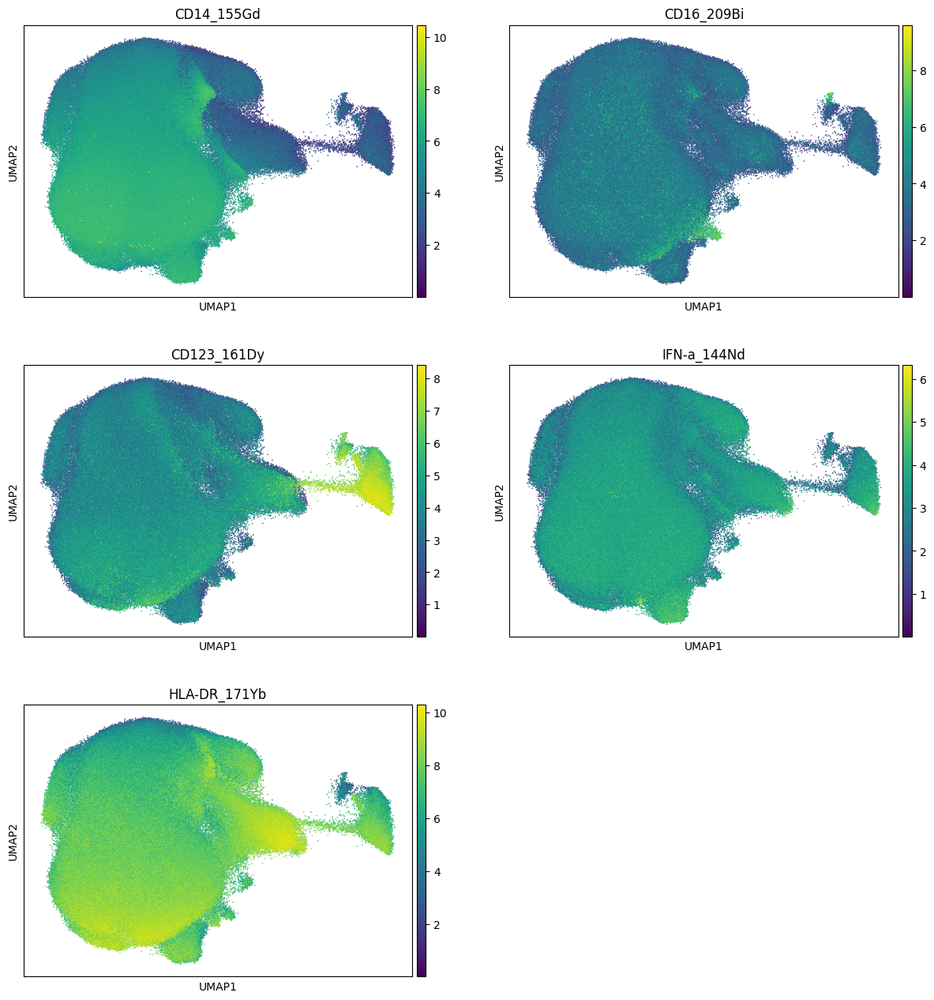

In [226]:
markers_sub =[
    'CD14_155Gd',
    'CD16_209Bi','CD123_161Dy','IFN-a_144Nd','HLA-DR_171Yb'
]

sc.pl.umap(adata_filtered, color=markers_sub, cmap='viridis', ncols=2, size=5)

In [197]:
import scanpy as sc
import pandas as pd

# 假设已经创建了一个 adata 对象并计算了 leigen 聚类结果
# 使用 `rank_genes_groups` 进行差异表达分析
sc.tl.rank_genes_groups(adata_filtered, groupby='leiden', groups=['9'], method='t-test')

# 获取差异表达的结果
result = adata_filtered.uns['rank_genes_groups']

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


ValueError: If using all scalar values, you must pass an index

In [199]:
import pandas as pd

# 提取 cluster9 的数据
cluster9_genes = result['names']['9']  # 获取cluster 9的基因名称
cluster9_logfc = result['logfoldchanges']['9']  # 获取cluster 9的log fold change
cluster9_pvals_adj = result['pvals_adj']['9']  # 获取cluster 9的adjusted p-value

# 将数据转换为DataFrame
cluster9_marker_df = pd.DataFrame({
    'gene': cluster9_genes,
    'logfoldchanges': cluster9_logfc,
    'pvals_adj': cluster9_pvals_adj
})

# 筛选出显著标记物 (例如 p-value < 0.05)
significant_markers_cluster9 = cluster9_marker_df[cluster9_marker_df['pvals_adj'] < 0.05]

# 查看前几个显著标记物
print(significant_markers_cluster9.head())

           gene  logfoldchanges  pvals_adj
0   CD123_161Dy        6.084183        0.0
1  CD45RA_170Er        1.275242        0.0
2     CD4_115In        1.239115        0.0
3    GZMB_169Tm        1.275546        0.0
4  pSTAT1_175Lu        0.844397        0.0


In [203]:
# 统计每个cluster的细胞数
cluster_counts = adata_filtered.obs['leiden'].value_counts()

# 显示结果
print(cluster_counts)

leiden
0    303427
2    279916
1    205045
6     55467
7     30350
9     19549
3     14652
8     10331
5      8029
4      6194
Name: count, dtype: int64


In [204]:
# 选择 cluster9 的细胞
cluster9_cells = adata_filtered[adata_filtered.obs['leiden'] == '9']

# 查看 cluster9 细胞来源于哪些 samples
cluster9_samples = cluster9_cells.obs['Sample'].value_counts()

# 显示结果
print(cluster9_samples)

Sample
A012_V0    776
A012_V1    518
A012_V4    410
A061_V0    396
A012_V3    340
          ... 
A033_V1     20
A008_V8     13
A008_V7      7
A033_V0      6
A008_V9      1
Name: count, Length: 156, dtype: int64


In [206]:
import scanpy as sc
import pandas as pd

# 假设已经创建了一个 adata 对象并计算了 leigen 聚类结果
# 使用 `rank_genes_groups` 进行差异表达分析
sc.tl.rank_genes_groups(adata_filtered, groupby='leiden', groups=['7'], method='t-test')

# 获取差异表达的结果
result = adata_filtered.uns['rank_genes_groups']

# 提取 cluster9 的数据
cluster7_genes = result['names']['7']  # 获取cluster 9的基因名称
cluster7_logfc = result['logfoldchanges']['7']  # 获取cluster 9的log fold change
cluster7_pvals_adj = result['pvals_adj']['7']  # 获取cluster 9的adjusted p-value

# 将数据转换为DataFrame
cluster7_marker_df = pd.DataFrame({
    'gene': cluster7_genes,
    'logfoldchanges': cluster7_logfc,
    'pvals_adj': cluster7_pvals_adj
})

# 筛选出显著标记物 (例如 p-value < 0.05)
significant_markers_cluster7 = cluster7_marker_df[cluster7_marker_df['pvals_adj'] < 0.05]

# 查看前几个显著标记物
print(significant_markers_cluster7.head())

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)
           gene  logfoldchanges  pvals_adj
0    DNA1_191Ir        0.664693        0.0
1    DNA2_193Ir        0.650961        0.0
2     IgD_142Nd        0.681862        0.0
3  CASP-8_156Gd        0.558348        0.0
4   IFN-a_144Nd        0.391316        0.0


In [207]:
significant_markers_cluster7

,gene,logfoldchanges,pvals_adj
0,DNA1_191Ir,0.664693,0.000000e+00
1,DNA2_193Ir,0.650961,0.000000e+00
2,IgD_142Nd,0.681862,0.000000e+00
3,CASP-8_156Gd,0.558348,0.000000e+00
4,IFN-a_144Nd,0.391316,0.000000e+00
5,LIVE_198Pt,0.313992,0.000000e+00
6,CD45-5_116Cd,0.123096,2.062900e-12
10,Offset,-0.400251,3.717241e-112
11,Time,-0.208662,1.627887e-120
12,Arginase-1_164Dy,-0.230839,2.212869e-184


In [247]:
import scanpy as sc
import pandas as pd

# 假设已经创建了一个 adata 对象并计算了 leigen 聚类结果
# 使用 `rank_genes_groups` 进行差异表达分析
sc.tl.rank_genes_groups(adata_filtered, groupby='leiden', groups=['6'], method='t-test')

# 获取差异表达的结果
result = adata_filtered.uns['rank_genes_groups']

# 提取 cluster9 的数据
cluster6_genes = result['names']['6']  # 获取cluster 9的基因名称
cluster6_logfc = result['logfoldchanges']['6']  # 获取cluster 9的log fold change
cluster6_pvals_adj = result['pvals_adj']['6']  # 获取cluster 9的adjusted p-value

# 将数据转换为DataFrame
cluster6_marker_df = pd.DataFrame({
    'gene': cluster6_genes,
    'logfoldchanges': cluster6_logfc,
    'pvals_adj': cluster6_pvals_adj
})

# 筛选出显著标记物 (例如 p-value < 0.05)
significant_markers_cluster6 = cluster6_marker_df[cluster6_marker_df['pvals_adj'] < 0.05]

# 查看前几个显著标记物
print(significant_markers_cluster6)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)
                gene  logfoldchanges      pvals_adj
0       HLA-DR_171Yb        2.467555   0.000000e+00
1       pSTAT1_175Lu        1.806652   0.000000e+00
2        Ki-67_162Dy        1.737966   0.000000e+00
3         GZMB_169Tm        0.999685   0.000000e+00
4        IFN-g_172Yb        1.419636   0.000000e+00
5       CASP-8_156Gd        0.683709   0.000000e+00
6        CD11c_173Yb        0.942996   0.000000e+00
7        CD123_161Dy        1.136381   0.000000e+00
8      H3K27ac_148Nd        0.546388   0.000000e+00
9         CD19_174Yb        0.638391   0.000000e+00
10      CD45RA_170Er        0.363961   0.000

In [248]:
cluster_anno = {
    "0": "cMono",
    "1": "cMono",
    "2": "cMono",
    "3": "cMono",
    "4": "cMono",
    "5": "cMono",
    "6":"pDC",
    "7":"unknown",
    "8":"cMono",
    "9":"pDC",
}

In [249]:
adata_filtered.obs["subtype"] = adata_filtered.obs["leiden"].map(cluster_anno)

In [250]:
import pandas as pd

# 从 AnnData 对象的 obs 中提取 cell_id 和 subtype 列
cell_subtype_df = adata_filtered.obs[['ID', 'subtype']]

# 查看前几行以确认数据
print(cell_subtype_df.head())

# 保存为 CSV 文件


          ID subtype
358912  A004   cMono
190700  A004   cMono
48464   A004   cMono
116342  A004   cMono
259387  A004   cMono


In [251]:
cell_info_df = pd.DataFrame({
    'cellid': adata_filtered.obs.index,  # 细胞ID
    'sample': adata_filtered.obs['Sample'],  # 样本ID
    'celltype': adata_filtered.obs['celltype'],  # 细胞类型
    'subtype': adata_filtered.obs['subtype'] # 细胞亚型  
})
cell_info_df.head()
cell_info_df.to_csv('/public/users/xueyupeng/VZV/lvzhu/record/subtype_annotations_Mono.csv', index=False)

,cellid,sample,celltype,subtype
358912,358912,A004_V1,Monocyte,cMono
190700,190700,A004_V1,Monocyte,cMono
48464,48464,A004_V1,Monocyte,cMono
116342,116342,A004_V1,Monocyte,cMono
259387,259387,A004_V1,Monocyte,cMono


In [245]:
adata_filtered.obs.index

Index(['358912', '190700', '48464', '116342', '259387', '147662', '297955',
       '254209', '10343', '197079',
       ...
       '57944-30', '111859-28', '45721-33', '165442-24', '166298-29',
       '71195-18', '183943-17', '138574-25', '133854-19', '151250-26'],
      dtype='object', length=932960)